# Deep-Sea Classification: Context Reliance & Depth Degradation
This notebook imports from the project's `.py` modules and runs the full pipeline on Colab's GPU.

# Analysis
Loads saved results from the training pipeline and runs all statistical
analyses: CRS–degradation correlation, baseline comparisons, robustness
checks, bootstrap confidence intervals, and CRS variance analysis.
No GPU required.

In [2]:
# Install any extra packages not on Colab by default
!pip install fathomnet grad-cam

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for grad-cam: filename=grad_cam-1.5.7-py3-none-any.whl size=53345 sha256=7f6b39286dd9ea8f1ac7a0a7fc396464ccdf603e9ffe97dd2ee82d5b544229b7
  Stored in directory: /root/.cache/pip/wheels/91/36/f0/c2367865493d51b13369769181beca14603d17d6539a5922e3
Successfully built grad-cam
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [grad-cam]


In [3]:
from google.colab import drive
drive.mount('/content/drive')

PROJECT_DIR = '/content/drive/Shareddrives/CV-Project'

import sys, os
sys.path.insert(0, PROJECT_DIR)
os.chdir(PROJECT_DIR)

import importlib
import pandas as pd
import config
import analysis
import extensions

# Load saved results
per_species_df = pd.read_csv(os.path.join(config.RESULTS_DIR, 'results.csv'), index_col='species')

# Reconstruct per-species dicts used by analysis functions
crs_scores   = per_species_df['crs'].dropna().to_dict()
degradation  = per_species_df['degradation'].dropna().to_dict()
shallow_acc  = per_species_df['shallow_acc'].dropna().to_dict()
uniform_crs  = per_species_df['uniform_crs'].dropna().to_dict()
gaussian_crs = per_species_df['gaussian_crs'].dropna().to_dict()

# Load cached predictions
int_preds = pd.read_csv(os.path.join(config.RESULTS_DIR, 'intervention_predictions.csv'))

all_ic = pd.read_csv(os.path.join(config.RESULTS_DIR, 'image_crs.csv'))
image_crs = {s: all_ic[all_ic['split'] == s].drop(columns='split') for s in ['shallow', 'deep']}

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## CRS vs degradation

139 / 314 species qualify (>= 5 shallow and deep test crops, CRS available)
Spearman over 139 species
Spearman ρ = -0.047, p = 0.5820


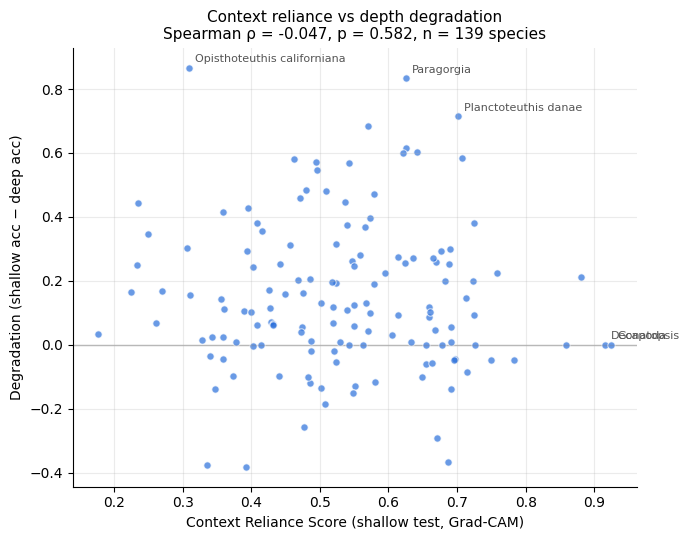

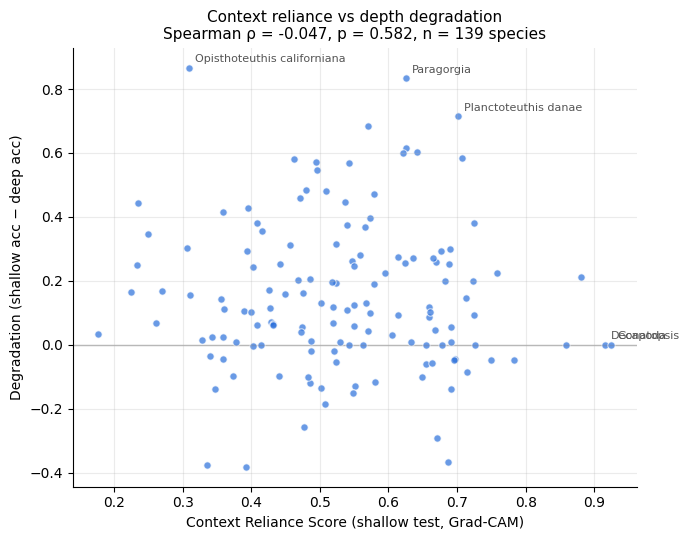

In [4]:
# Core hypothesis test - correlation between depth degradation and context relience

# will have to check for a minimum number of test images in deep and shallow
# currently images with 1 test shallow will be weight equally to those with hundereds
# and those with 0 will give crs_score NaN
qualifying = analysis.select_qualifying_species(per_species_df, min_test_n=5)
rho, p_value = analysis.spearman_correlation(crs_scores, degradation, species=qualifying)
print(f'Spearman ρ = {rho:.3f}, p = {p_value:.4f}')
analysis.plot_crs_vs_degradation(crs_scores, degradation, species=qualifying, rho=rho,
                                 p_value=p_value, save_path='results/crs_vs_degradation.png')

### Checking against baselines

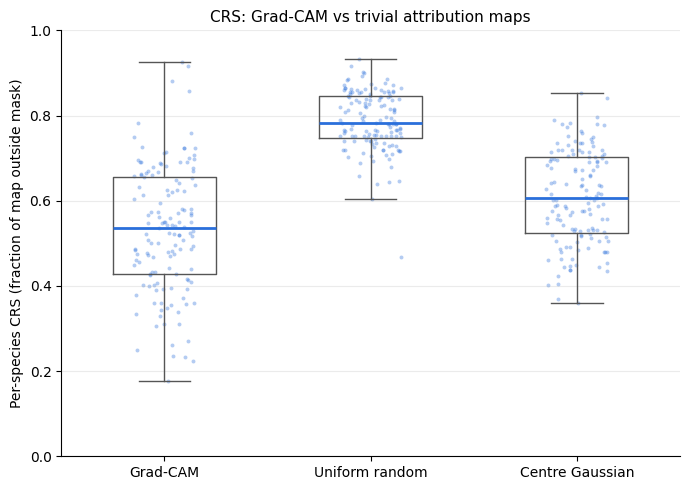

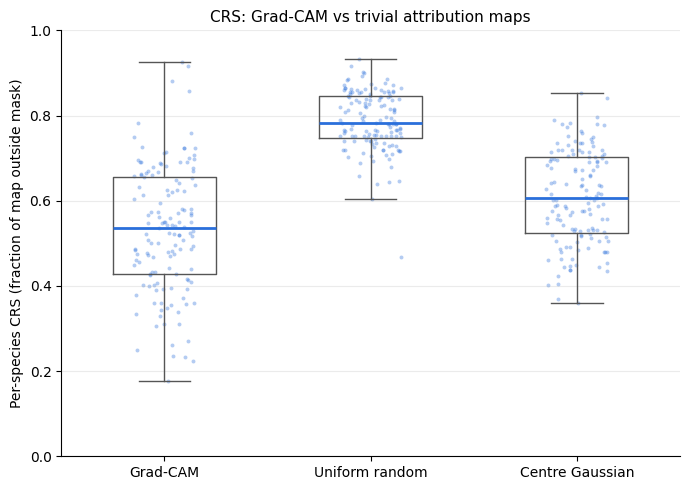

In [5]:
# Checking against baselines
# crs vs organism size (is high crs just because organism is larger in crop?)
analysis.plot_baseline_comparison(crs_scores, uniform_crs, gaussian_crs, species=qualifying,
                                  save_path='results/baseline_crs.png')
# degradation vs control
#analysis.plot_control_comparison(degradation, control_results, save_path='results/control_comparison.png')

## Spearman Correlation
Correlation between degradation and context-reliance

In [6]:
# Summary table
summary = analysis.generate_summary_table(
    crs_scores, degradation, rho, p_value, species=qualifying,
    baselines={'Uniform random': uniform_crs, 'Centre Gaussian': gaussian_crs})
summary.to_csv('results/correlation_summary.csv')
summary

# TODO: attention map/crs on shallow-only vs control model, deep vs shallow images
# (2x2 grid per species)
# does attribution move to the background in deep images?
# and does the control model attribution stay on the organism?


Spearman over 139 species
Spearman over 139 species


,n_species,mean_crs,spearman_rho,p_value
method,,,,
Grad-CAM,139,0.533186,-0.047086,0.582024
Uniform random,139,0.787930,-0.007857,0.926862
Centre Gaussian,139,0.608397,0.017733,0.835853


In [7]:
# 1. Does the result depend on how many test crops a species needs?
for n in [5, 10, 20]:
    q = analysis.select_qualifying_species(per_species_df, min_test_n=n)
    r, p = analysis.spearman_correlation(crs_scores, degradation, species=q)
    print(f"min_test_n={n}: n_species={len(q)}, rho={r:.3f}, p={p:.3f}")

# 2. Species the model barely recognises even in shallow water can't degrade much,
#    which can hide a relationship. Re-run on species it learned reasonably well.
learned = [s for s in qualifying if shallow_acc[s] >= 0.3]
r, p = analysis.spearman_correlation(crs_scores, degradation, species=learned)
print(f"shallow_acc >= 0.3: n_species={len(learned)}, rho={r:.3f}, p={p:.3f}")

139 / 314 species qualify (>= 5 shallow and deep test crops, CRS available)
Spearman over 139 species
min_test_n=5: n_species=139, rho=-0.047, p=0.582
98 / 314 species qualify (>= 10 shallow and deep test crops, CRS available)
Spearman over 98 species
min_test_n=10: n_species=98, rho=0.051, p=0.619
66 / 314 species qualify (>= 20 shallow and deep test crops, CRS available)
Spearman over 66 species
min_test_n=20: n_species=66, rho=-0.067, p=0.594
Spearman over 110 species
shallow_acc >= 0.3: n_species=110, rho=0.036, p=0.712


## Background Intervention Results

In [8]:
importlib.reload(extensions)
boot = extensions.bootstrap_intervention(int_preds, species=qualifying)
boot.to_csv(os.path.join(config.RESULTS_DIR, 'intervention_bootstrap.csv'), index=False)
display(boot.round(3))

Bootstrap over 139 species, 2000 resamples


,model,mode,metric,estimate,ci_low,ci_high,significant
0,shallow,Background greyed,degradation,0.038,0.015,0.063,True
1,shallow,Background greyed,reduction,0.113,0.076,0.151,True
2,shallow,Background greyed,retention_gap,0.052,0.003,0.104,True
3,control,Background greyed,degradation,-0.036,-0.069,-0.003,True
4,control,Background greyed,reduction,-0.017,-0.054,0.022,False
5,control,Background greyed,retention_gap,0.019,-0.026,0.064,False
6,shallow - control,Background greyed,retention_gap,0.033,-0.021,0.092,False
7,shallow,Background blurred,degradation,0.096,0.066,0.127,True
8,shallow,Background blurred,reduction,0.055,0.026,0.084,True
9,shallow,Background blurred,retention_gap,0.033,-0.018,0.083,False


### Within-species CRS variance vs degradation
The image-level analysis shows CRS predicts errors within species, but species-level mean CRS doesn't predict degradation. Does CRS *variance* bridge that gap? Species with inconsistent context reliance (high variance) may be more vulnerable to distribution shift than species with stable CRS.

CRS std vs degradation: rho = -0.128, p = 0.134, n = 139 species
CRS iqr vs degradation: rho = 0.003, p = 0.971, n = 139 species
CRS mean vs degradation: rho = -0.047, p = 0.582, n = 139 species


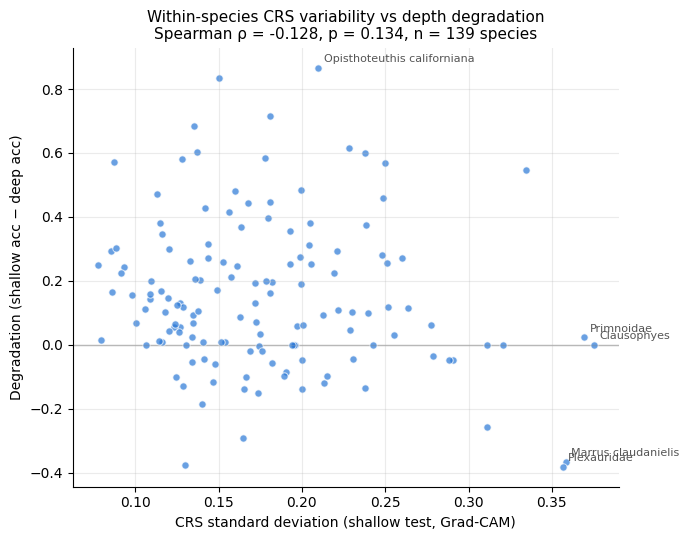

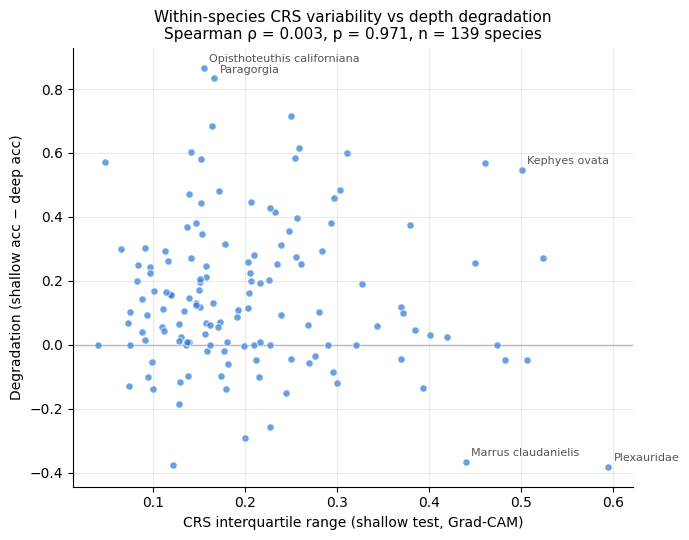

,mean,std,iqr,count,degradation
count,139.000,139.000,139.000,139.000,139.000
mean,0.533,0.178,0.209,97.302,0.151
std,0.147,0.064,0.111,155.019,0.235
min,0.177,0.077,0.041,5.000,-0.381
25%,0.428,0.129,0.135,13.000,0.000
50%,0.536,0.167,0.177,29.000,0.112
75%,0.655,0.211,0.256,111.000,0.274
max,0.925,0.375,0.595,755.000,0.867


In [9]:
importlib.reload(extensions)

# Per-species CRS std, IQR, and mean vs degradation (shallow image CRS)
var_df, var_stats = extensions.crs_variance_analysis(
    image_crs['shallow'], degradation, species=qualifying)

# Scatter plot for CRS std
rho_std, p_std, n_std = var_stats['std']
extensions.plot_crs_variance_vs_degradation(
    var_df, metric='std', rho=rho_std, p_value=p_std,
    save_path='results/crs_variance_vs_degradation.png')

# Also show IQR (more robust to outliers)
rho_iqr, p_iqr, n_iqr = var_stats['iqr']
extensions.plot_crs_variance_vs_degradation(
    var_df, metric='iqr', rho=rho_iqr, p_value=p_iqr)

display(var_df[['mean', 'std', 'iqr', 'count', 'degradation']].describe().round(3))